In [2]:
# If needed:
# pip install qutip numpy matplotlib scipy

import numpy as np
import matplotlib.pyplot as plt
import qutip as qt

In [3]:
# ----------------------------
# Parameters
# ----------------------------
N = 60  # Fock cutoff
alpha = 1.0  # harmonic restoring parameter
beta = 0.02  # Duffing quartic strength
omega = np.sqrt(alpha)

tmax = 80
nt = 400
tlist = np.linspace(0, tmax, nt)

xi_coh = 2.0  # coherent-state amplitude

In [4]:
# ----------------------------
# Operators
# ----------------------------
a = qt.destroy(N)
adag = a.dag()
n = adag * a

q = (a + adag) / np.sqrt(2 * omega)
p = 1j * np.sqrt(omega / 2) * (adag - a)

# ----------------------------
# Full Duffing Hamiltonian
# Powers here use the finite QuTiP quadratures, not an extended-space sandwich.
# ----------------------------
H_duff = 0.5 * p**2 + 0.5 * alpha * q**2 + 0.25 * beta * q**4

# ----------------------------
# Kerr/RWA Hamiltonian
# ----------------------------
K_eff = 3 * beta / (8 * omega**2)
Omega = omega + K_eff

H_kerr = Omega * n + K_eff * n**2

In [5]:
# ----------------------------
# 1. Spectrum comparison
# ----------------------------
num_levels = 20

E_duff = np.array(H_duff.eigenenergies()[:num_levels])
E_kerr = np.array(H_kerr.eigenenergies()[:num_levels])

# remove ground-state offset
E_duff_shift = E_duff - E_duff[0]
E_kerr_shift = E_kerr - E_kerr[0]

spectral_error = np.abs(E_duff_shift - E_kerr_shift)

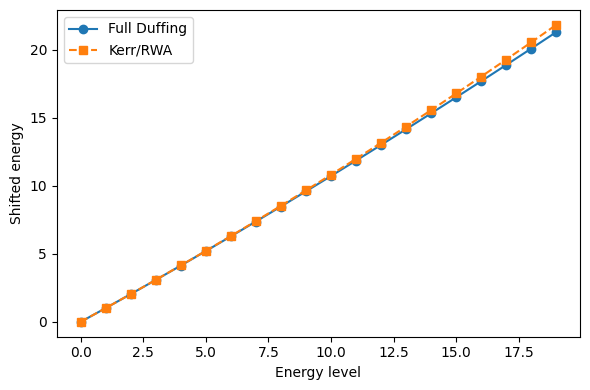

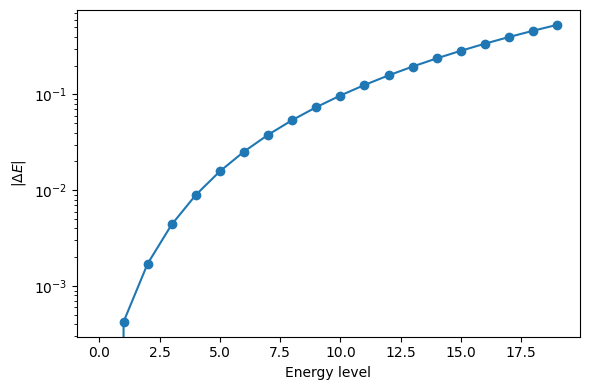

In [6]:
plt.figure(figsize=(6, 4))
plt.plot(range(num_levels), E_duff_shift, "o-", label="Full Duffing")
plt.plot(range(num_levels), E_kerr_shift, "s--", label="Kerr/RWA")
plt.xlabel("Energy level")
plt.ylabel("Shifted energy")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.semilogy(range(num_levels), spectral_error, "o-")
plt.xlabel("Energy level")
plt.ylabel(r"$|\Delta E|$")
plt.tight_layout()
plt.show()

In [7]:
# ----------------------------
# 2. Time-evolution comparison
# ----------------------------
psi0 = qt.coherent(N, xi_coh)

result_duff = qt.sesolve(
    H_duff, psi0, tlist, e_ops=[q, n], options={"store_states": True}
)

result_kerr = qt.sesolve(
    H_kerr, psi0, tlist, e_ops=[q, n], options={"store_states": True}
)

states_duff = result_duff.states
states_kerr = result_kerr.states

fidelity = np.array(
    [abs(states_duff[i].overlap(states_kerr[i])) ** 2 for i in range(len(states_duff))]
)

q_duff = np.real(result_duff.expect[0])
q_kerr = np.real(result_kerr.expect[0])

n_duff = np.real(result_duff.expect[1])
n_kerr = np.real(result_kerr.expect[1])

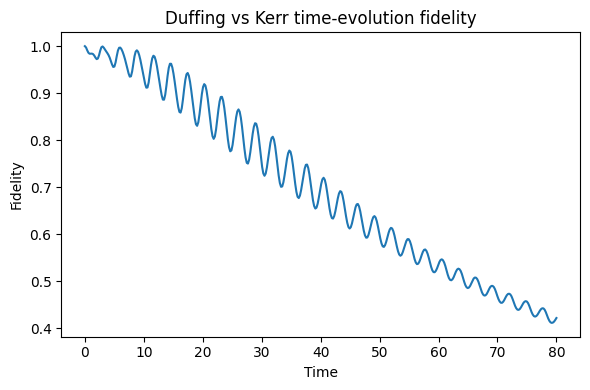

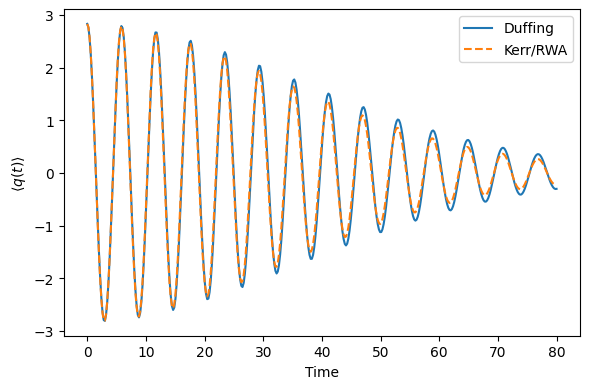

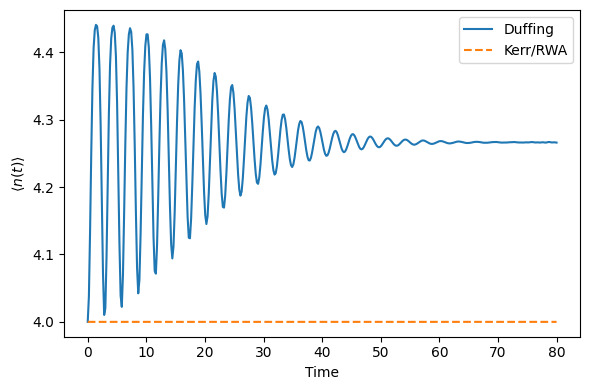

In [8]:
plt.figure(figsize=(6, 4))
plt.plot(tlist, fidelity)
plt.xlabel("Time")
plt.ylabel("Fidelity")
plt.title("Duffing vs Kerr time-evolution fidelity")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(tlist, q_duff, label="Duffing")
plt.plot(tlist, q_kerr, "--", label="Kerr/RWA")
plt.xlabel("Time")
plt.ylabel(r"$\langle q(t) \rangle$")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.plot(tlist, n_duff, label="Duffing")
plt.plot(tlist, n_kerr, "--", label="Kerr/RWA")
plt.xlabel("Time")
plt.ylabel(r"$\langle n(t) \rangle$")
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
# ----------------------------
# 3. Scan beta and excitation amplitude
# ----------------------------
beta_values = np.linspace(0.001, 0.08, 20)
amp_values = np.linspace(0.5, 4.0, 15)

# This scan runs two trajectories for each of 20 x 15 parameter pairs.
min_fidelity_map = np.zeros((len(beta_values), len(amp_values)))

for i, beta_i in enumerate(beta_values):
    K_i = 3 * beta_i / (8 * omega**2)
    Omega_i = omega + K_i

    H_duff_i = 0.5 * p**2 + 0.5 * alpha * q**2 + 0.25 * beta_i * q**4
    H_kerr_i = Omega_i * n + K_i * n**2

    for j, amp_j in enumerate(amp_values):
        psi0_j = qt.coherent(N, amp_j)

        sol_d = qt.sesolve(H_duff_i, psi0_j, tlist)
        sol_k = qt.sesolve(H_kerr_i, psi0_j, tlist)

        F = np.array(
            [
                abs((sol_d.states[m].dag() * sol_k.states[m])) ** 2
                for m in range(len(tlist))
            ]
        )

        min_fidelity_map[i, j] = np.min(F)

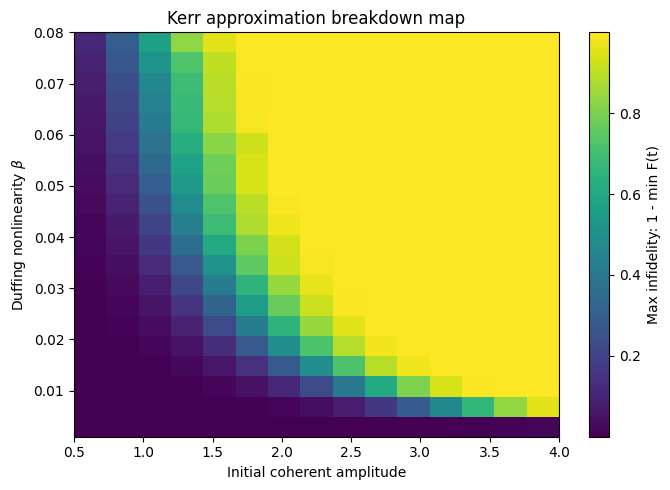

In [10]:
plt.figure(figsize=(7, 5))
plt.imshow(
    1 - min_fidelity_map,
    origin="lower",
    aspect="auto",
    extent=[amp_values[0], amp_values[-1], beta_values[0], beta_values[-1]],
)
plt.colorbar(label="Max infidelity: 1 - min F(t)")
plt.xlabel("Initial coherent amplitude")
plt.ylabel(r"Duffing nonlinearity $\beta$")
plt.title("Kerr approximation breakdown map")
plt.tight_layout()
plt.show()

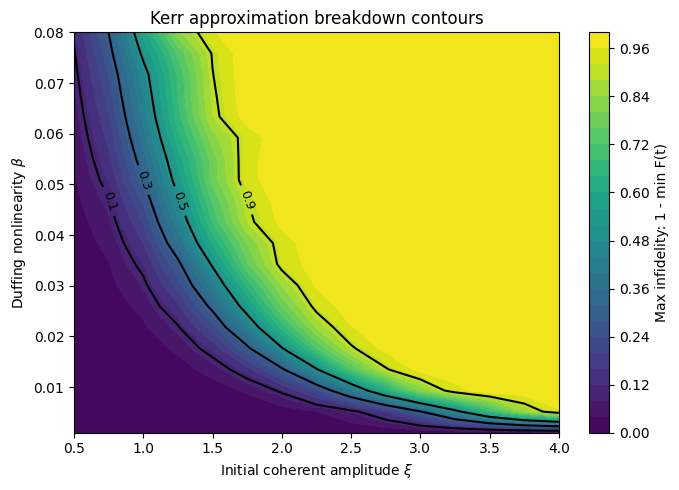

In [11]:
plt.figure(figsize=(7, 5))

X, Y = np.meshgrid(amp_values, beta_values)
Z = 1 - min_fidelity_map

plt.contourf(X, Y, Z, levels=30)
plt.colorbar(label="Max infidelity: 1 - min F(t)")

# validity threshold contours
cs = plt.contour(X, Y, Z, levels=[0.1, 0.3, 0.5, 0.9], colors="black")
plt.clabel(cs, inline=True, fontsize=9)

plt.xlabel(r"Initial coherent amplitude $\xi$")
plt.ylabel(r"Duffing nonlinearity $\beta$")
plt.title("Kerr approximation breakdown contours")
plt.tight_layout()
plt.show()

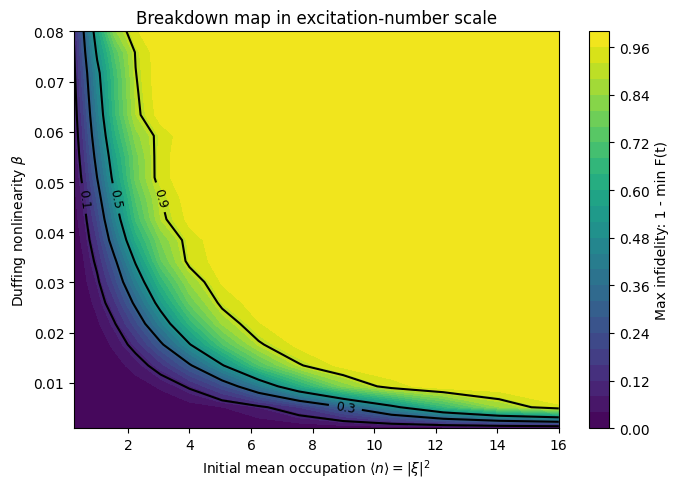

In [12]:
nbar_values = amp_values**2

plt.figure(figsize=(7, 5))

X, Y = np.meshgrid(nbar_values, beta_values)
Z = 1 - min_fidelity_map

plt.contourf(X, Y, Z, levels=30)
plt.colorbar(label="Max infidelity: 1 - min F(t)")

cs = plt.contour(X, Y, Z, levels=[0.1, 0.3, 0.5, 0.9], colors="black")
plt.clabel(cs, inline=True, fontsize=9)

plt.xlabel(r"Initial mean occupation $\langle n \rangle = |\xi|^2$")
plt.ylabel(r"Duffing nonlinearity $\beta$")
plt.title("Breakdown map in excitation-number scale")
plt.tight_layout()
plt.show()

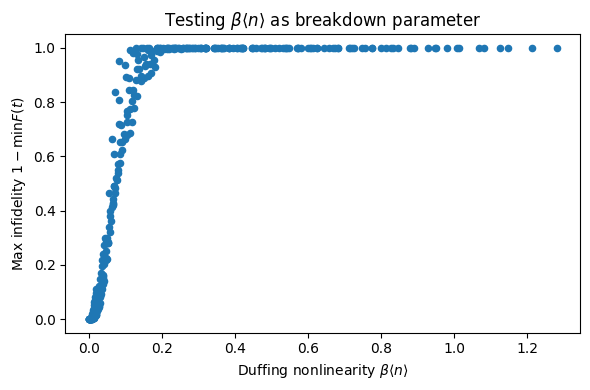

In [13]:
BN = np.outer(beta_values, nbar_values)
Z = 1 - min_fidelity_map

plt.figure(figsize=(6, 4))
plt.scatter(BN.flatten(), Z.flatten(), s=20)
plt.xlabel(r"Duffing nonlinearity $\beta \langle n \rangle$")
plt.ylabel(r"Max infidelity $1 - \min F(t)$")
plt.title(r"Testing $\beta \langle n \rangle$ as breakdown parameter")
plt.tight_layout()
plt.show()

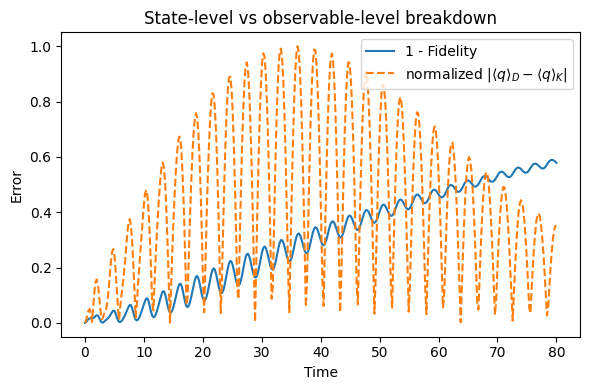

In [14]:
q_error = np.abs(q_duff - q_kerr)
infidelity = 1 - fidelity

plt.figure(figsize=(6, 4))
plt.plot(tlist, infidelity, label="1 - Fidelity")
plt.plot(
    tlist,
    q_error / np.max(q_error),
    "--",
    label=r"normalized $|\langle q \rangle_D - \langle q \rangle_K|$",
)
plt.xlabel("Time")
plt.ylabel("Error")
plt.legend()
plt.title("State-level vs observable-level breakdown")
plt.tight_layout()
plt.show()

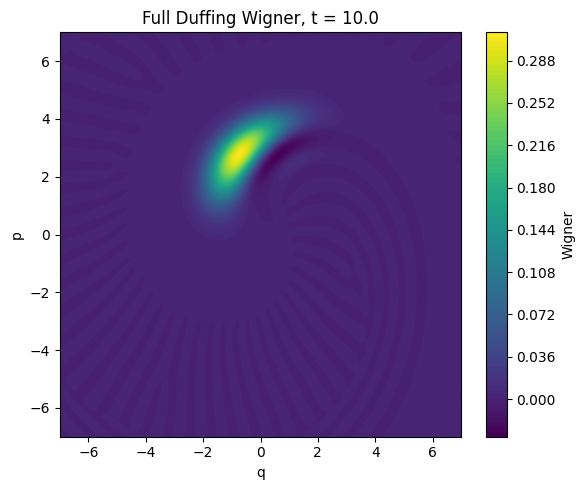

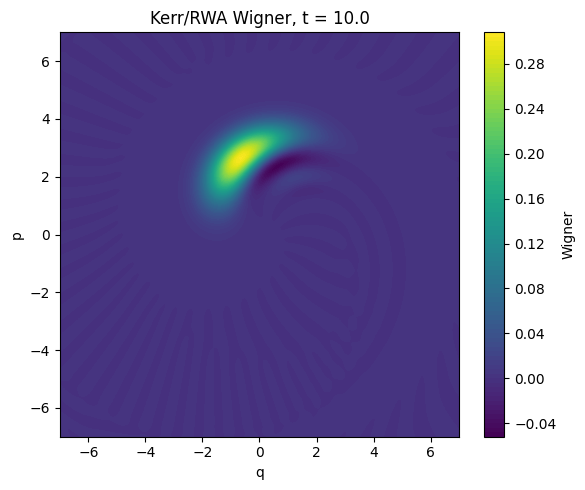

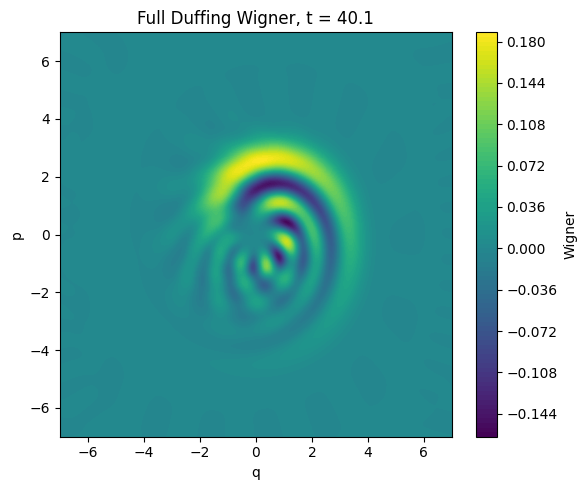

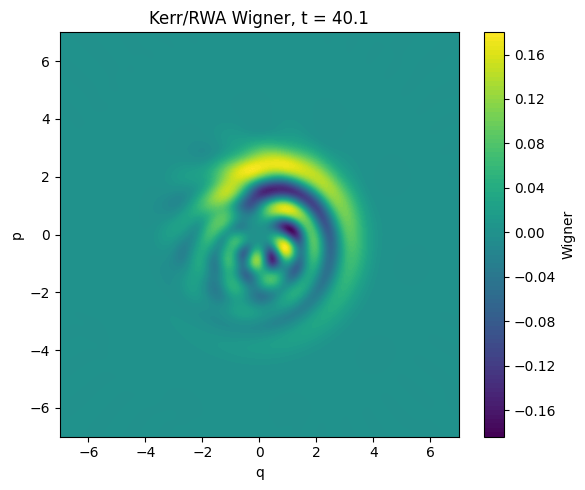

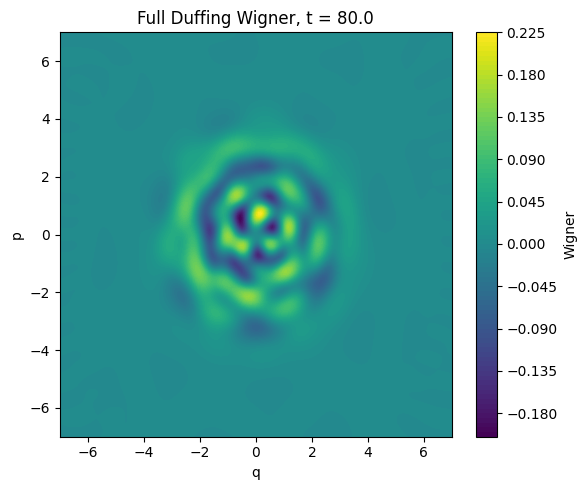

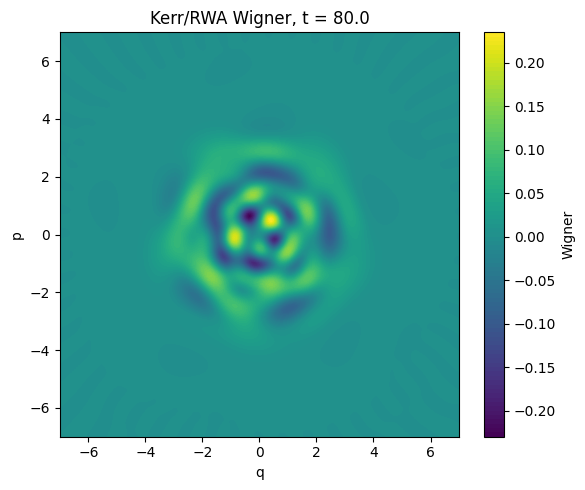

In [15]:
xvec = np.linspace(-7, 7, 200)

times_to_plot = [10, 40, 80]

for target_time in times_to_plot:
    idx = np.argmin(np.abs(tlist - target_time))

    W_duff = qt.wigner(states_duff[idx], xvec, xvec)
    W_kerr = qt.wigner(states_kerr[idx], xvec, xvec)

    plt.figure(figsize=(6, 5))
    plt.contourf(xvec, xvec, W_duff, levels=100)
    plt.colorbar(label="Wigner")
    plt.xlabel("q")
    plt.ylabel("p")
    plt.title(f"Full Duffing Wigner, t = {tlist[idx]:.1f}")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(6, 5))
    plt.contourf(xvec, xvec, W_kerr, levels=100)
    plt.colorbar(label="Wigner")
    plt.xlabel("q")
    plt.ylabel("p")
    plt.title(f"Kerr/RWA Wigner, t = {tlist[idx]:.1f}")
    plt.tight_layout()
    plt.show()

In [16]:
target_time = 40
idx = np.argmin(np.abs(tlist - target_time))

W_duff = qt.wigner(states_duff[idx], xvec, xvec)
W_kerr = qt.wigner(states_kerr[idx], xvec, xvec)

W_diff = W_duff - W_kerr

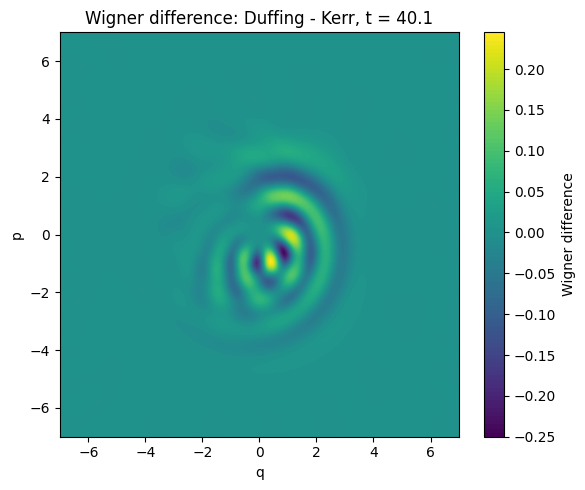

In [17]:
plt.figure(figsize=(6, 5))
plt.contourf(xvec, xvec, W_diff, levels=100)
plt.colorbar(label="Wigner difference")
plt.xlabel("q")
plt.ylabel("p")
plt.title(f"Wigner difference: Duffing - Kerr, t = {tlist[idx]:.1f}")
plt.tight_layout()
plt.show()

In [18]:
N_values = [40, 60, 80, 100, 120]

beta_test = 0.02
amp_test = 2.0
num_levels = 15

spectral_errors_by_N = {}

for Ntest in N_values:
    a = qt.destroy(Ntest)
    adag = a.dag()
    n = adag * a

    omega = np.sqrt(alpha)
    q = (a + adag) / np.sqrt(2 * omega)
    p = 1j * np.sqrt(omega / 2) * (adag - a)

    H_duff = 0.5 * p**2 + 0.5 * alpha * q**2 + 0.25 * beta_test * q**4

    K_eff = 3 * beta_test / (8 * omega**2)
    Omega = omega + K_eff
    H_kerr = Omega * n + K_eff * n**2

    E_duff = np.array(H_duff.eigenenergies()[:num_levels])
    E_kerr = np.array(H_kerr.eigenenergies()[:num_levels])

    E_duff -= E_duff[0]
    E_kerr -= E_kerr[0]

    spectral_errors_by_N[Ntest] = np.abs(E_duff - E_kerr)

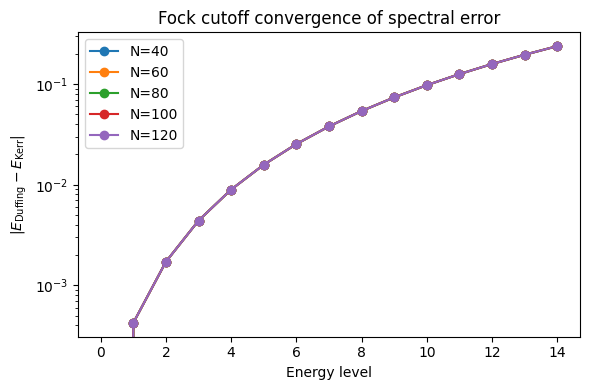

In [19]:
plt.figure(figsize=(6, 4))
for Ntest in N_values:
    plt.semilogy(
        range(num_levels), spectral_errors_by_N[Ntest], "o-", label=f"N={Ntest}"
    )

plt.xlabel("Energy level")
plt.ylabel(r"$|E_{\text{Duffing}} - E_{\text{Kerr}}|$")
plt.title("Fock cutoff convergence of spectral error")
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
from skimage import measure
from scipy.optimize import curve_fit

Z = 1 - min_fidelity_map
X, Y = np.meshgrid(nbar_values, beta_values)

threshold = 0.1

contours = measure.find_contours(Z, threshold)

# choose longest contour
contour = max(contours, key=len)

# convert contour indices to physical values
row_idx = contour[:, 0]
col_idx = contour[:, 1]

beta_boundary = np.interp(row_idx, np.arange(len(beta_values)), beta_values)
nbar_boundary = np.interp(col_idx, np.arange(len(nbar_values)), nbar_values)

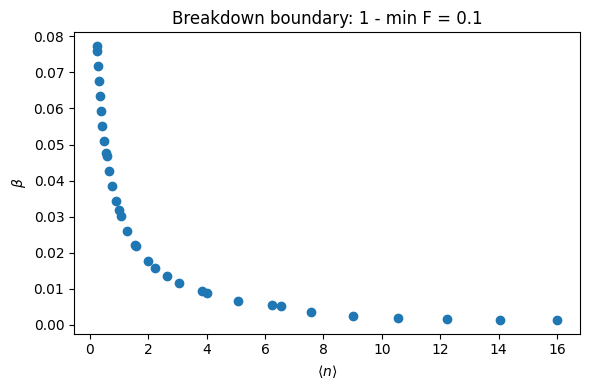

In [21]:
plt.figure(figsize=(6, 4))
plt.plot(nbar_boundary, beta_boundary, "o")
plt.xlabel(r"$\langle n \rangle$")
plt.ylabel(r"$\beta$")
plt.title(f"Breakdown boundary: 1 - min F = {threshold}")
plt.tight_layout()
plt.show()

In [22]:
# fit beta = C / nbar^p
def power_law(nbar, C, p):
    return C / (nbar**p)


popt, pcov = curve_fit(power_law, nbar_boundary, beta_boundary)

C_fit, p_fit = popt

nbar_fit = np.linspace(min(nbar_boundary), max(nbar_boundary), 200)
beta_fit = power_law(nbar_fit, C_fit, p_fit)

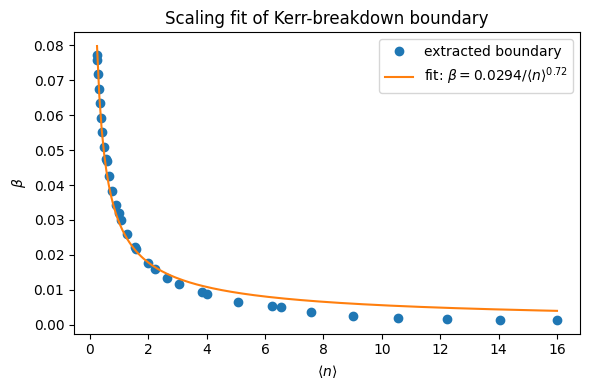

C = 0.02941196854000639
p = 0.7196794625094152


In [23]:
plt.figure(figsize=(6, 4))
plt.plot(nbar_boundary, beta_boundary, "o", label="extracted boundary")
plt.plot(
    nbar_fit,
    beta_fit,
    "-",
    label=rf"fit: $\beta = {C_fit:.3g}/\langle n \rangle^{{{p_fit:.2f}}}$",
)
plt.xlabel(r"$\langle n \rangle$")
plt.ylabel(r"$\beta$")
plt.title("Scaling fit of Kerr-breakdown boundary")
plt.legend()
plt.tight_layout()
plt.show()

print("C =", C_fit)
print("p =", p_fit)

In [24]:
# Make sure this matches the current operator dimension
N = 120

a = qt.destroy(N)
adag = a.dag()
n = adag * a

omega = np.sqrt(alpha)

q = (a + adag) / np.sqrt(2 * omega)
p = 1j * np.sqrt(omega / 2) * (adag - a)

H_duff = 0.5 * p**2 + 0.5 * alpha * q**2 + 0.25 * beta * q**4

K_eff = 3 * beta / (8 * omega**2)
Omega = omega + K_eff
H_kerr = Omega * n + K_eff * n**2

# IMPORTANT: recreate psi0 with same N
psi0 = qt.coherent(N, xi_coh)

a2 = a * a

result_duff = qt.sesolve(
    H_duff,
    psi0,
    tlist,
    e_ops=[q, p, n, q * q, p * p, a2],
    options={"store_states": True},
)

result_kerr = qt.sesolve(
    H_kerr,
    psi0,
    tlist,
    e_ops=[q, p, n, q * q, p * p, a2],
    options={"store_states": True},
)

q_duff = np.real(result_duff.expect[0])
p_duff = np.real(result_duff.expect[1])
n_duff = np.real(result_duff.expect[2])
q2_duff = np.real(result_duff.expect[3])
p2_duff = np.real(result_duff.expect[4])
a2_duff = result_duff.expect[5]

q_kerr = np.real(result_kerr.expect[0])
p_kerr = np.real(result_kerr.expect[1])
n_kerr = np.real(result_kerr.expect[2])
q2_kerr = np.real(result_kerr.expect[3])
p2_kerr = np.real(result_kerr.expect[4])
a2_kerr = result_kerr.expect[5]

varq_duff = q2_duff - q_duff**2
varq_kerr = q2_kerr - q_kerr**2

varp_duff = p2_duff - p_duff**2
varp_kerr = p2_kerr - p_kerr**2

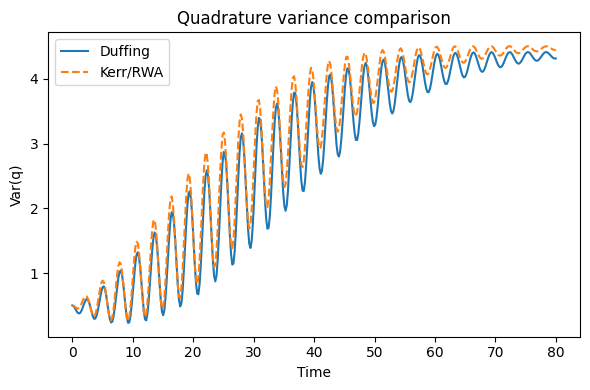

In [25]:
plt.figure(figsize=(6, 4))
plt.plot(tlist, varq_duff, label="Duffing")
plt.plot(tlist, varq_kerr, "--", label="Kerr/RWA")
plt.xlabel("Time")
plt.ylabel("Var(q)")
plt.title("Quadrature variance comparison")
plt.legend()
plt.tight_layout()
plt.show()

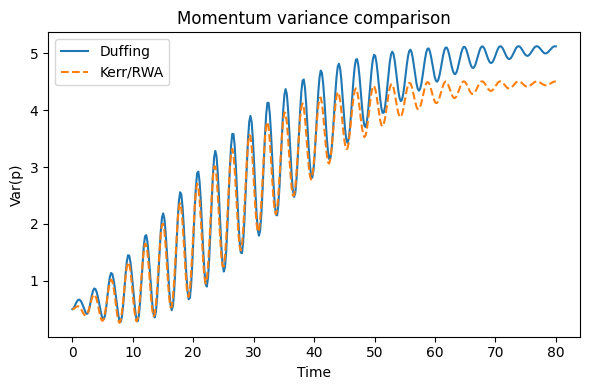

In [26]:
plt.figure(figsize=(6, 4))
plt.plot(tlist, varp_duff, label="Duffing")
plt.plot(tlist, varp_kerr, "--", label="Kerr/RWA")
plt.xlabel("Time")
plt.ylabel("Var(p)")
plt.title("Momentum variance comparison")
plt.legend()
plt.tight_layout()
plt.show()

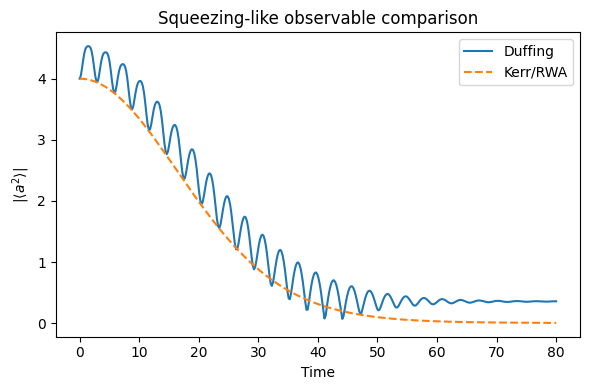

In [27]:
plt.figure(figsize=(6, 4))
plt.plot(tlist, np.abs(a2_duff), label="Duffing")
plt.plot(tlist, np.abs(a2_kerr), "--", label="Kerr/RWA")
plt.xlabel("Time")
plt.ylabel(r"$|\langle a^2 \rangle|$")
plt.title("Squeezing-like observable comparison")
plt.legend()
plt.tight_layout()
plt.show()

In [28]:
def wigner_negativity(state, xvec):
    W = qt.wigner(state, xvec, xvec)

    dx = xvec[1] - xvec[0]
    dp = xvec[1] - xvec[0]

    # Finite-grid quadrature: tails outside xvec and grid spacing affect this estimate.
    negativity = 0.5 * (np.sum(np.abs(W)) * dx * dp - 1.0)
    return negativity


xvec = np.linspace(-7, 7, 200)

neg_duff = []
neg_kerr = []

for i in range(len(tlist)):
    neg_duff.append(wigner_negativity(states_duff[i], xvec))
    neg_kerr.append(wigner_negativity(states_kerr[i], xvec))

neg_duff = np.array(neg_duff)
neg_kerr = np.array(neg_kerr)

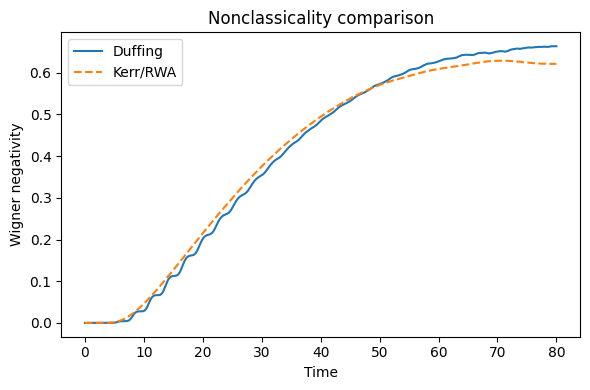

In [29]:
plt.figure(figsize=(6, 4))
plt.plot(tlist, neg_duff, label="Duffing")
plt.plot(tlist, neg_kerr, "--", label="Kerr/RWA")
plt.xlabel("Time")
plt.ylabel("Wigner negativity")
plt.title("Nonclassicality comparison")
plt.legend()
plt.tight_layout()
plt.show()